# PyTorch Mask R-CNN Training for Image Forgery Detection

This notebook trains a Mask R-CNN model using PyTorch's torchvision to detect and segment forged regions in images.

## Overview
- **Model**: Mask R-CNN with ResNet-50 FPN backbone
- **Task**: Instance segmentation of forged regions
- **Dataset**: Forged images with corresponding mask files (.npy)

## Requirements
- torch
- torchvision
- numpy
- PIL/Pillow
- matplotlib
- tqdm


In [1]:
!nvidia-smi

Mon Nov 24 23:53:10 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P0             46W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
#upload your kaggle.json API key from kaggle.
from google.colab import files
files.upload()

In [3]:
!mkdir -p /root/.config/kaggle
!mv kaggle.json /root/.config/kaggle

In [4]:
!kaggle competitions download -c recodai-luc-scientific-image-forgery-detection
!unzip /content/recodai-luc-scientific-image-forgery-detection.zip

Streaming output truncated to the last 5000 lines.
  inflating: train_images/forged/20569.png  
  inflating: train_images/forged/20577.png  
  inflating: train_images/forged/20578.png  
  inflating: train_images/forged/20587.png  
  inflating: train_images/forged/20619.png  
  inflating: train_images/forged/2064.png  
  inflating: train_images/forged/20645.png  
  inflating: train_images/forged/20662.png  
  inflating: train_images/forged/20666.png  
  inflating: train_images/forged/20736.png  
  inflating: train_images/forged/20749.png  
  inflating: train_images/forged/20751.png  
  inflating: train_images/forged/20752.png  
  inflating: train_images/forged/20753.png  
  inflating: train_images/forged/20755.png  
  inflating: train_images/forged/20764.png  
  inflating: train_images/forged/20768.png  
  inflating: train_images/forged/20795.png  
  inflating: train_images/forged/20800.png  
  inflating: train_images/forged/20816.png  
  inflating: train_images/forged/20819.png  
  inf

In [5]:
%pip install torch
%pip install torchvision
%pip install numpy
%pip install Pillow
%pip install matplotlib
%pip install tqdm

## 1. Imports and Setup


In [6]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm import tqdm
import json
from datetime import datetime

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")


Using device: cuda
GPU: NVIDIA A100-SXM4-40GB
CUDA Version: 12.6


## 2. Dataset Configuration


In [10]:
# Dataset paths
DATA_DIR = "recodai-luc-scientific-image-forgery-detection"
FORGED_DIR = os.path.join(DATA_DIR, "train_images", "forged")
MASK_DIR = os.path.join(DATA_DIR, "train_masks")

# Verify paths exist
print(f"Forged images directory: {FORGED_DIR}")
print(f"Exists: {os.path.exists(FORGED_DIR)}")
print(f"\nMask directory: {MASK_DIR}")
print(f"Exists: {os.path.exists(MASK_DIR)}")

if os.path.exists(FORGED_DIR):
    num_forged = len([f for f in os.listdir(FORGED_DIR) if f.endswith(('.png', '.jpg', '.jpeg'))])
    print(f"\nNumber of forged images: {num_forged}")

if os.path.exists(MASK_DIR):
    num_masks = len([f for f in os.listdir(MASK_DIR) if f.endswith('.npy')])
    print(f"Number of mask files: {num_masks}")


Forged images directory: recodai-luc-scientific-image-forgery-detection/train_images/forged
Exists: True

Mask directory: recodai-luc-scientific-image-forgery-detection/train_masks
Exists: True

Number of forged images: 2751
Number of mask files: 2751


## 3. Dataset Class


In [11]:
class ForgeryDataset(Dataset):
    """PyTorch Dataset for image forgery detection with masks."""

    def __init__(self, forged_dir, mask_dir, transform=None, train=True):
        """
        Args:
            forged_dir: Path to directory containing forged images
            mask_dir: Path to directory containing mask files (.npy)
            transform: Optional transform to be applied to images
            train: If True, use training split (80%), else validation (20%)
        """
        self.forged_dir = forged_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.train = train

        # Get all forged images
        self.image_files = [f for f in os.listdir(forged_dir)
                           if f.endswith(('.png', '.jpg', '.jpeg'))]

        # 80/20 train/val split
        np.random.seed(42)
        np.random.shuffle(self.image_files)
        split_idx = int(len(self.image_files) * 0.8)

        if train:
            self.image_files = self.image_files[:split_idx]
        else:
            self.image_files = self.image_files[split_idx:]

        print(f"Loaded {len(self.image_files)} {'training' if train else 'validation'} images")

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        # Load image
        img_path = os.path.join(self.forged_dir, self.image_files[idx])
        image = Image.open(img_path).convert('RGB')

        # Get base name for mask
        base_name = os.path.splitext(self.image_files[idx])[0]
        mask_path = os.path.join(self.mask_dir, f"{base_name}.npy")

        # Load mask
        if os.path.exists(mask_path):
            mask_array = np.load(mask_path)
            # Handle different mask shapes
            if len(mask_array.shape) == 3:
                mask_array = mask_array[:, :, 0] if mask_array.shape[2] > 0 else mask_array.sum(axis=2)
            mask_array = (mask_array > 0).astype(np.uint8)
        else:
            # No mask found - create empty mask
            mask_array = np.zeros((image.size[1], image.size[0]), dtype=np.uint8)

        # Resize mask to match image if needed
        if mask_array.shape[:2] != (image.size[1], image.size[0]):
            mask_pil = Image.fromarray(mask_array)
            mask_pil = mask_pil.resize((image.size[0], image.size[1]), Image.NEAREST)
            mask_array = np.array(mask_pil)

        # Convert to tensor
        if self.transform:
            image = self.transform(image)
        else:
            # Default transform: convert to tensor
            image = transforms.ToTensor()(image)

        # Prepare targets for Mask R-CNN
        # Mask R-CNN expects:
        # - boxes: [N, 4] in (x1, y1, x2, y2) format
        # - labels: [N] class labels (1 = forged_region)
        # - masks: [N, H, W] binary masks

        # Find bounding box from mask
        rows = np.any(mask_array, axis=1)
        cols = np.any(mask_array, axis=0)

        if np.any(mask_array):
            y_min, y_max = np.where(rows)[0][[0, -1]]
            x_min, x_max = np.where(cols)[0][[0, -1]]

            # Convert to (x1, y1, x2, y2) format
            boxes = torch.tensor([[x_min, y_min, x_max, y_max]], dtype=torch.float32)
            labels = torch.tensor([1], dtype=torch.int64)  # 1 = forged_region
            masks = torch.tensor(mask_array[np.newaxis, :, :], dtype=torch.uint8)
        else:
            # No forged region - empty targets
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            masks = torch.zeros((0, mask_array.shape[0], mask_array.shape[1]), dtype=torch.uint8)

        target = {
            'boxes': boxes,
            'labels': labels,
            'masks': masks,
        }

        return image, target


## 4. Create Datasets and Data Loaders


In [12]:
# Create datasets
print("Loading datasets...")
train_dataset = ForgeryDataset(FORGED_DIR, MASK_DIR, train=True)
val_dataset = ForgeryDataset(FORGED_DIR, MASK_DIR, train=False)

# Custom collate function for batching
def collate_fn(batch):
    """Custom collate function for batching images and targets."""
    images = [item[0] for item in batch]
    targets = [item[1] for item in batch]
    return images, targets

# Training parameters
BATCH_SIZE = 4  # Adjust based on GPU memory
NUM_WORKERS = 4  # Adjust based on your system

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn
)

print(f"\nTrain batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")


Loading datasets...
Loaded 2200 training images
Loaded 551 validation images

Train batches: 550
Validation batches: 138


## 5. Visualize Sample Data

Let's check a sample image and mask to verify the dataset is loading correctly.


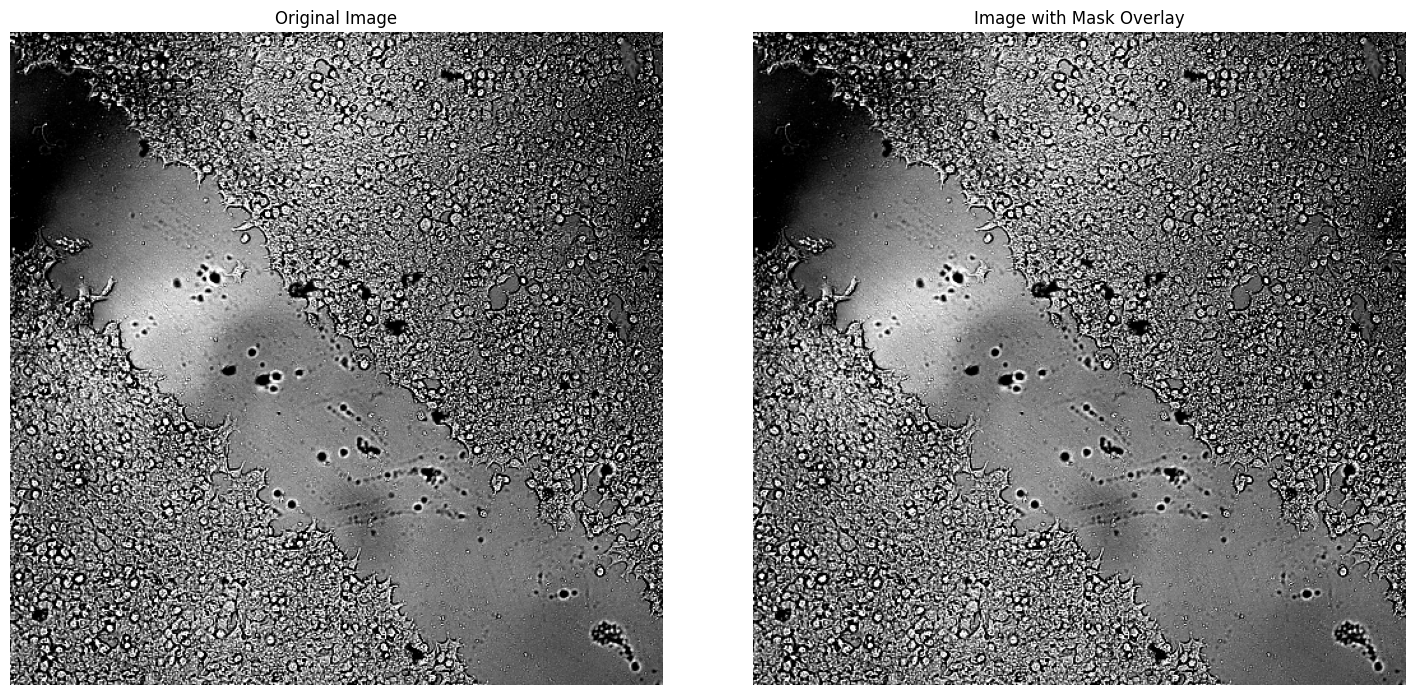

Image shape: (512, 512, 3)
Mask shape: No mask
Bounding box: No box


In [20]:
# Visualize a sample from the dataset
sample_idx = 0
image, target = train_dataset[sample_idx]

# Convert image tensor to numpy for visualization
img_np = image.permute(1, 2, 0).cpu().numpy()
img_np = (img_np * 255).astype(np.uint8)

# Get mask
mask = target['masks'][0].numpy() if target['masks'].shape[0] > 0 else None
box = target['boxes'][0].numpy() if target['boxes'].shape[0] > 0 else None

# Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(img_np)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(img_np)
if mask is not None:
    axes[1].imshow(mask, alpha=0.5, cmap='Reds')
    if box is not None:
        rect = patches.Rectangle(
            (box[0], box[1]), box[2] - box[0], box[3] - box[1],
            linewidth=2, edgecolor='green', facecolor='none'
        )
        axes[1].add_patch(rect)
axes[1].set_title('Image with Mask Overlay')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"Image shape: {img_np.shape}")
print(f"Mask shape: {mask.shape if mask is not None else 'No mask'}")
print(f"Bounding box: {box if box is not None else 'No box'}")


## 6. Model Setup


In [21]:
def get_model_instance_segmentation(num_classes):
    """Create a Mask R-CNN model with the specified number of classes.

    Args:
        num_classes: Number of classes (including background)
                     For forgery detection: 2 (background + forged_region)

    Returns:
        model: Mask R-CNN model
    """
    # Load pre-trained model
    model = maskrcnn_resnet50_fpn(pretrained=True)

    # Get number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # Replace the pre-trained head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    # Get number of input features for the mask classifier
    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden_layer = 256
    # Replace the mask predictor with a new one
    model.roi_heads.mask_predictor = MaskRCNNPredictor(
        in_features_mask,
        hidden_layer,
        num_classes
    )

    return model

# Create model
NUM_CLASSES = 2  # background + forged_region
print("Creating model...")
model = get_model_instance_segmentation(NUM_CLASSES)
model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Model created and moved to {device}")


Creating model...
Total parameters: 43,922,395
Trainable parameters: 43,699,995
Model created and moved to cuda


## 7. Training Functions


In [26]:
def train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq=10):
    """Train the model for one epoch."""
    model.train()
    metric_logger = {'loss': 0.0, 'loss_classifier': 0.0, 'loss_box_reg': 0.0,
                     'loss_mask': 0.0, 'loss_objectness': 0.0, 'loss_rpn_box_reg': 0.0}

    pbar = tqdm(data_loader, desc=f'Epoch {epoch}')

    for images, targets in pbar:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Forward pass
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        # Backward pass
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        # Update metrics
        metric_logger['loss'] += losses.item()
        for k, v in loss_dict.items():
            metric_logger[k] += v.item()

        # Update progress bar
        pbar.set_postfix({
            'loss': f"{losses.item():.4f}",
            'mask': f"{loss_dict['loss_mask'].item():.4f}"
        })

    # Average metrics
    for k in metric_logger:
        metric_logger[k] /= len(data_loader)

    return metric_logger


# FIXED evaluate function - Run this cell to replace the broken one
def evaluate(model, data_loader, device):
    """Evaluate the model on validation set."""
    # Temporarily set to train mode to get loss_dict (eval mode returns predictions)
    model.train()
    metric_logger = {'loss': 0.0, 'loss_classifier': 0.0, 'loss_box_reg': 0.0,
                     'loss_mask': 0.0, 'loss_objectness': 0.0, 'loss_rpn_box_reg': 0.0}

    with torch.no_grad():
        for images, targets in tqdm(data_loader, desc='Evaluating'):
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            # In train mode with targets, model returns loss_dict
            loss_dict = model(images, targets)

            # Check if loss_dict is actually a dict (should be)
            if isinstance(loss_dict, dict):
                losses = sum(loss for loss in loss_dict.values())
                metric_logger['loss'] += losses.item()
                for k, v in loss_dict.items():
                    metric_logger[k] += v.item()
            else:
                # If it's not a dict, something went wrong
                print(f"Warning: Expected dict, got {type(loss_dict)}")
                continue

    # Average metrics
    for k in metric_logger:
        metric_logger[k] /= len(data_loader)

    # Set back to eval mode
    model.eval()

    return metric_logger

print("✓ Fixed evaluate function loaded! This replaces the broken one.")
print("Now you can continue training from where it stopped.")


✓ Fixed evaluate function loaded! This replaces the broken one.
Now you can continue training from where it stopped.


## 8. Setup Optimizer and Learning Rate Scheduler


In [27]:
# Optimizer
LEARNING_RATE = 0.001
params = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.SGD(params, lr=LEARNING_RATE, momentum=0.9, weight_decay=0.0005)

# Learning rate scheduler
lr_scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

print(f"Optimizer: SGD with lr={LEARNING_RATE}, momentum=0.9")
print(f"LR Scheduler: StepLR (step_size=3, gamma=0.1)")


Optimizer: SGD with lr=0.001, momentum=0.9
LR Scheduler: StepLR (step_size=3, gamma=0.1)


## 9. Training Loop


In [28]:
# Training configuration
NUM_EPOCHS = 10  # Adjust as needed

# Create output directory
output_dir = 'checkpoints'
os.makedirs(output_dir, exist_ok=True)

# Training history
history = {
    'train_loss': [],
    'val_loss': [],
    'train_mask_loss': [],
    'val_mask_loss': []
}

print(f"Starting training for {NUM_EPOCHS} epochs...")
print("=" * 60)

best_val_loss = float('inf')


Starting training for 10 epochs...


In [29]:
# Training loop
for epoch in range(1, NUM_EPOCHS + 1):
    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")
    print("-" * 60)

    # Train
    train_metrics = train_one_epoch(model, optimizer, train_loader, device, epoch)
    history['train_loss'].append(train_metrics['loss'])
    history['train_mask_loss'].append(train_metrics['loss_mask'])

    # Validate
    val_metrics = evaluate(model, val_loader, device)
    history['val_loss'].append(val_metrics['loss'])
    history['val_mask_loss'].append(val_metrics['loss_mask'])

    # Update learning rate
    lr_scheduler.step()

    # Print metrics
    print(f"Train Loss: {train_metrics['loss']:.4f} | "
          f"Train Mask Loss: {train_metrics['loss_mask']:.4f}")
    print(f"Val Loss: {val_metrics['loss']:.4f} | "
          f"Val Mask Loss: {val_metrics['loss_mask']:.4f}")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")

    # Save best model
    if val_metrics['loss'] < best_val_loss:
        best_val_loss = val_metrics['loss']
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': val_metrics['loss'],
        }, os.path.join(output_dir, 'best_model.pth'))
        print(f"✓ Saved best model (val_loss: {best_val_loss:.4f})")

    # Save checkpoint
    if epoch % 5 == 0:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
        }, os.path.join(output_dir, f'checkpoint_epoch_{epoch}.pth'))
        print(f"✓ Saved checkpoint at epoch {epoch}")

print("\n" + "=" * 60)
print("Training complete!")
print(f"Best validation loss: {best_val_loss:.4f}")



Epoch 1/10
------------------------------------------------------------


Evaluating: 100%|██████████| 138/138 [00:17<00:00,  8.10it/s]


Train Loss: 0.2573 | Train Mask Loss: 0.1463
Val Loss: 0.3257 | Val Mask Loss: 0.2252
Learning Rate: 0.001000
✓ Saved best model (val_loss: 0.3257)

Epoch 2/10
------------------------------------------------------------


Evaluating: 100%|██████████| 138/138 [00:16<00:00,  8.15it/s]


Train Loss: 0.2395 | Train Mask Loss: 0.1445
Val Loss: 0.2900 | Val Mask Loss: 0.1789
Learning Rate: 0.001000
✓ Saved best model (val_loss: 0.2900)

Epoch 3/10
------------------------------------------------------------


...

Train Loss: 0.1924 | Train Mask Loss: 0.1165
Val Loss: 0.2817 | Val Mask Loss: 0.1813
Learning Rate: 0.000010

Epoch 9/10
------------------------------------------------------------


Evaluating: 100%|██████████| 138/138 [00:16<00:00,  8.16it/s]


Train Loss: 0.1931 | Train Mask Loss: 0.1173
Val Loss: 0.2804 | Val Mask Loss: 0.1788
Learning Rate: 0.000001

Epoch 10/10
------------------------------------------------------------


Evaluating: 100%|██████████| 138/138 [00:16<00:00,  8.15it/s]


Train Loss: 0.1984 | Train Mask Loss: 0.1230
Val Loss: 0.2781 | Val Mask Loss: 0.1784
Learning Rate: 0.000001
✓ Saved checkpoint at epoch 10

Training complete!
Best validation loss: 0.2727


## 10. Plot Training History


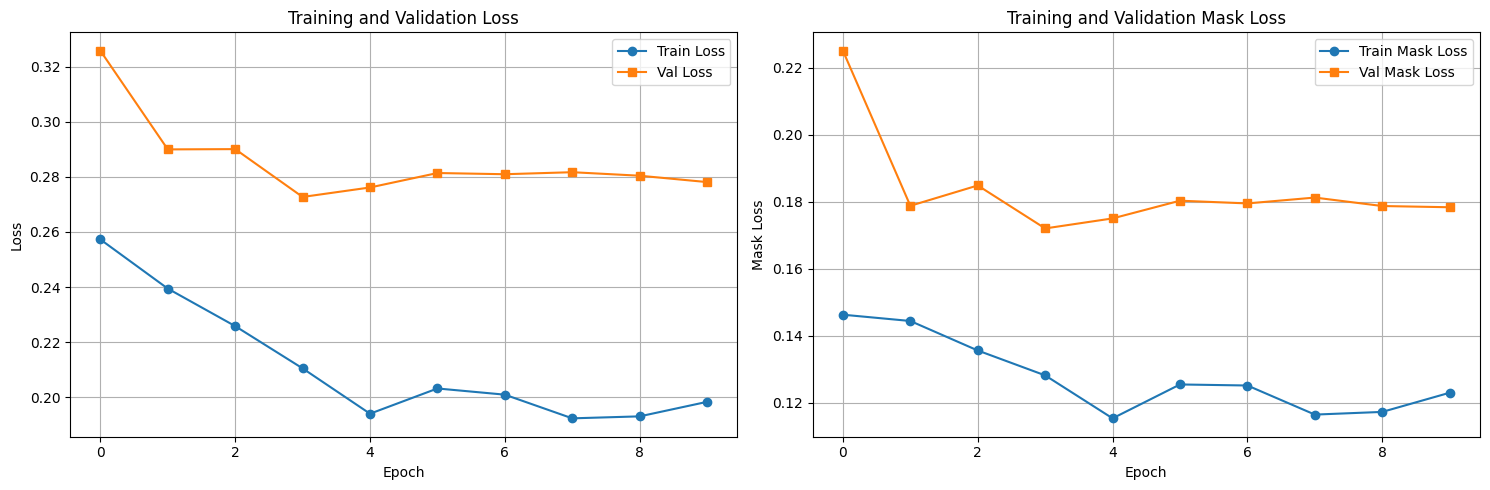

Training history saved to checkpoints/training_history.json


In [30]:
# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss plot
axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True)

# Mask loss plot
axes[1].plot(history['train_mask_loss'], label='Train Mask Loss', marker='o')
axes[1].plot(history['val_mask_loss'], label='Val Mask Loss', marker='s')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mask Loss')
axes[1].set_title('Training and Validation Mask Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

# Save training history
with open(os.path.join(output_dir, 'training_history.json'), 'w') as f:
    json.dump(history, f, indent=2)

print(f"Training history saved to {output_dir}/training_history.json")


## 11. Visualize Predictions


Generating predictions on validation set...


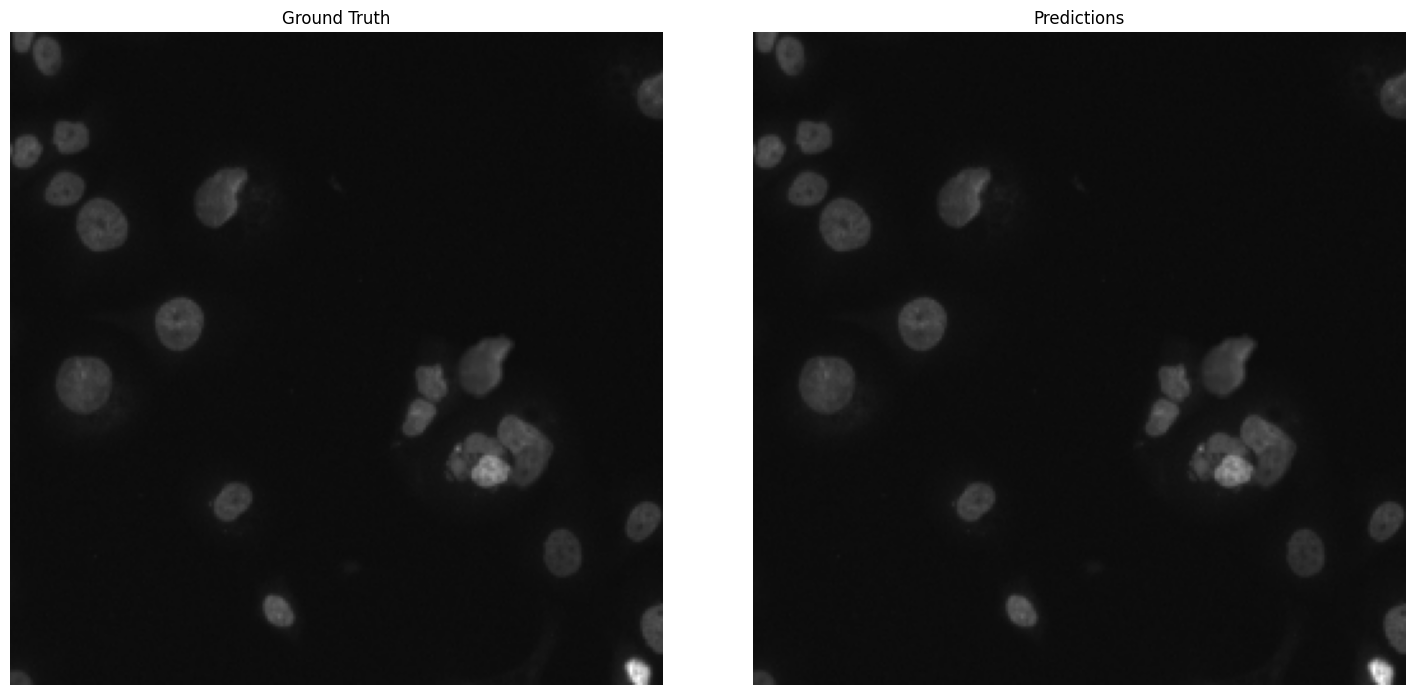

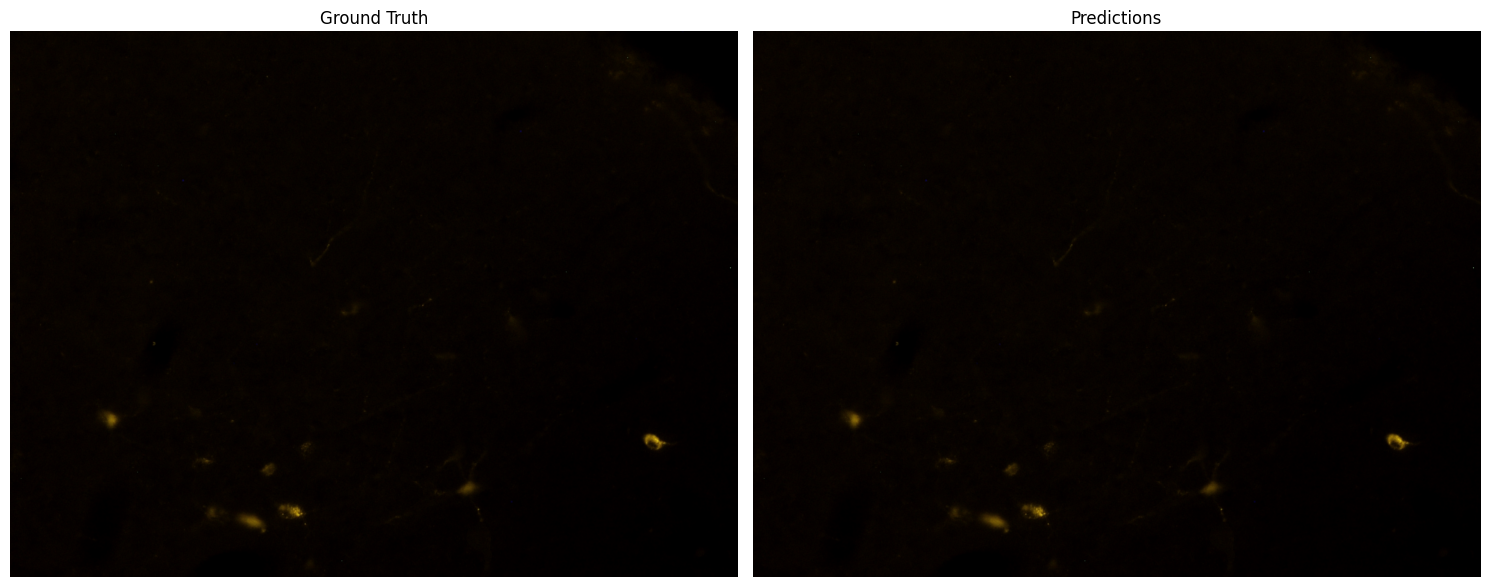

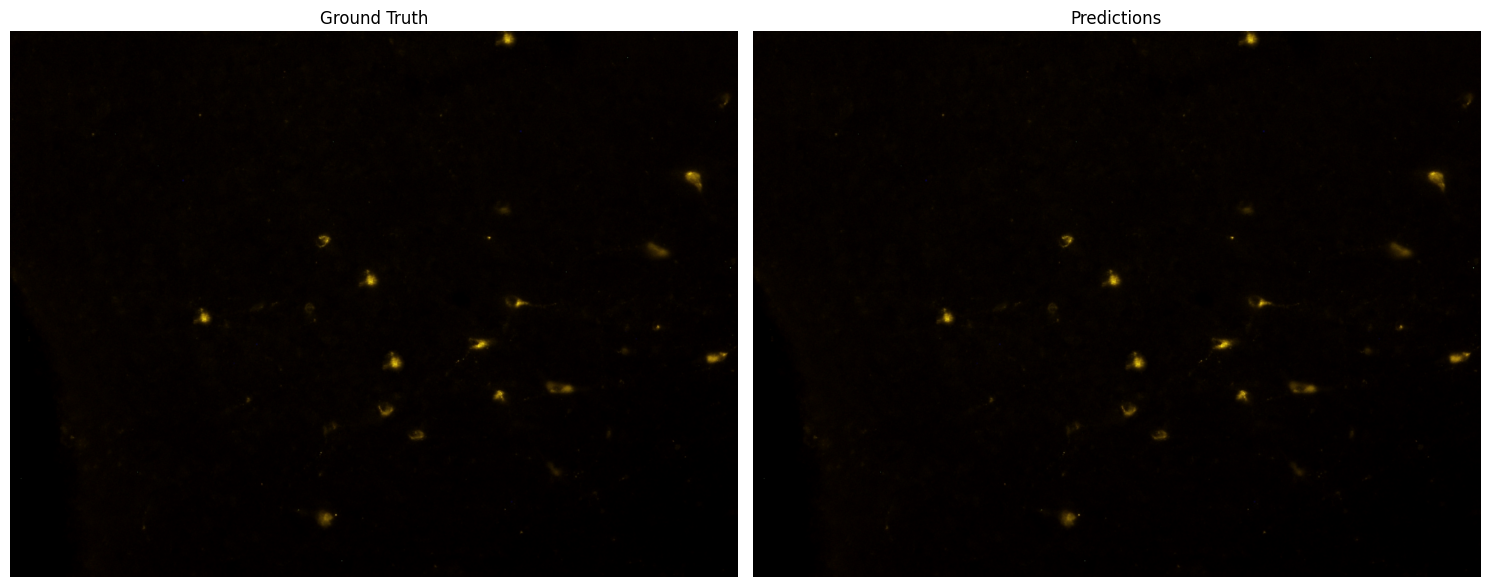

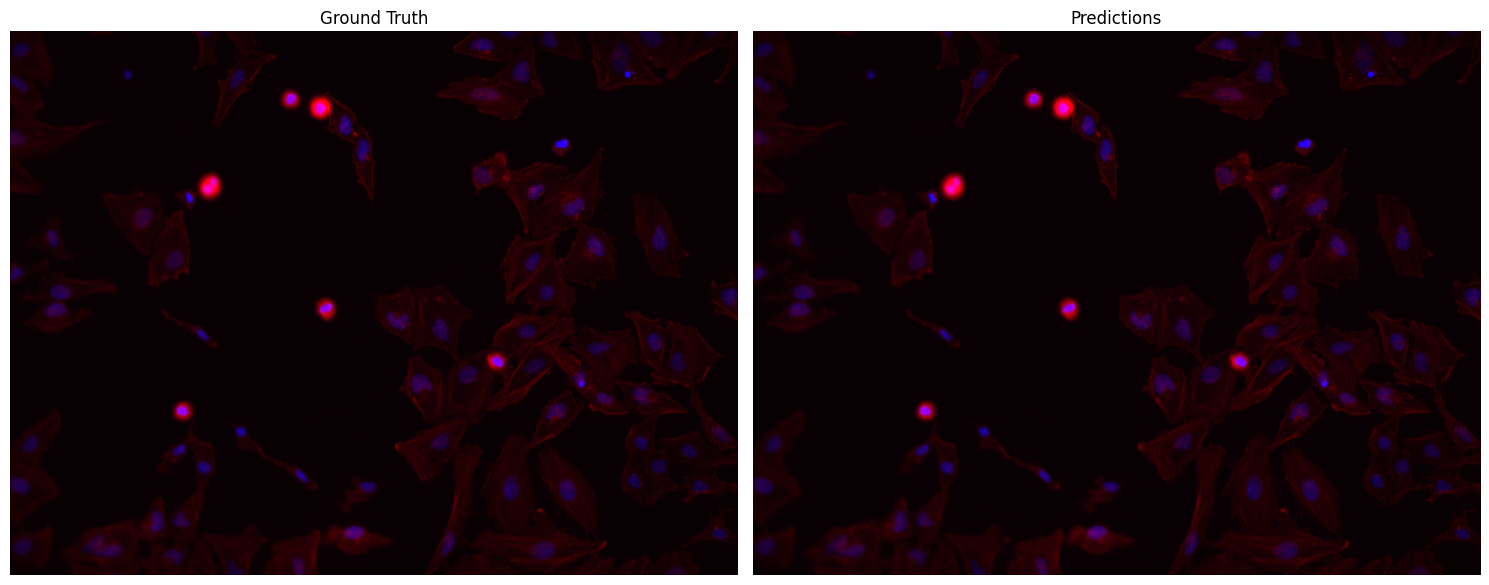

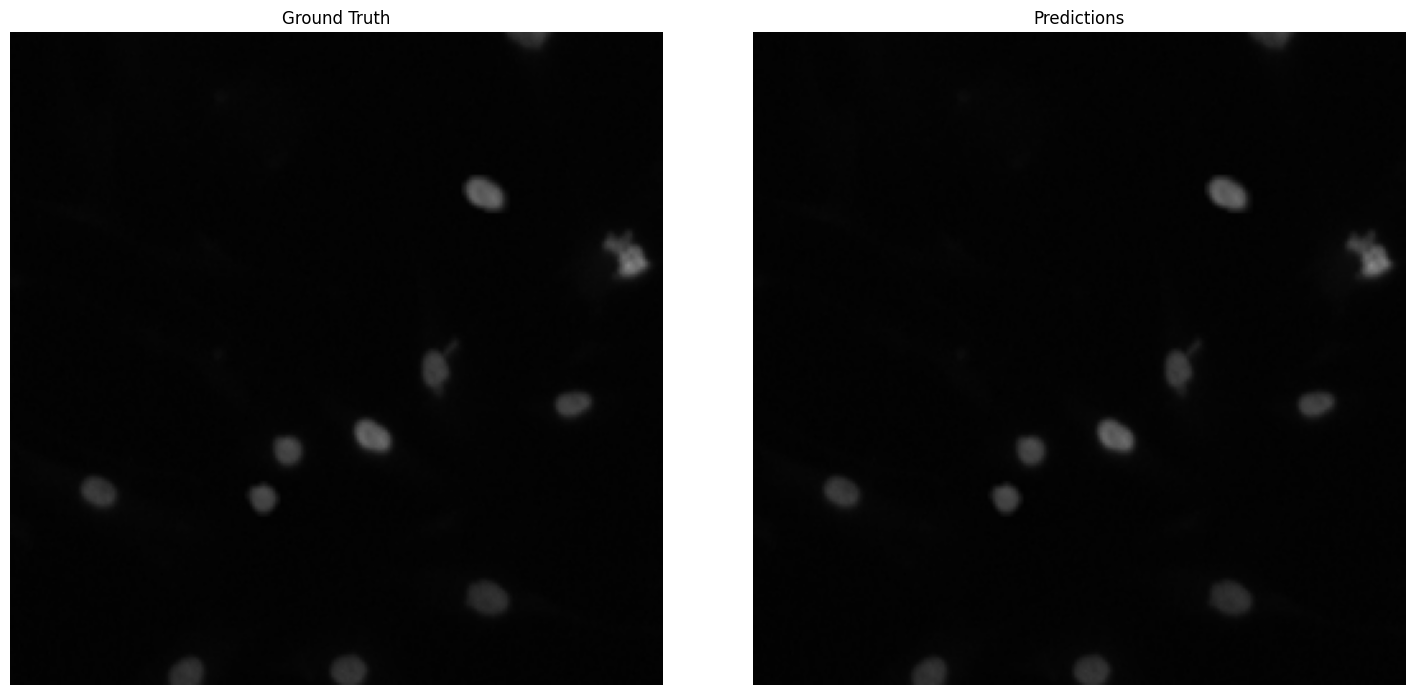

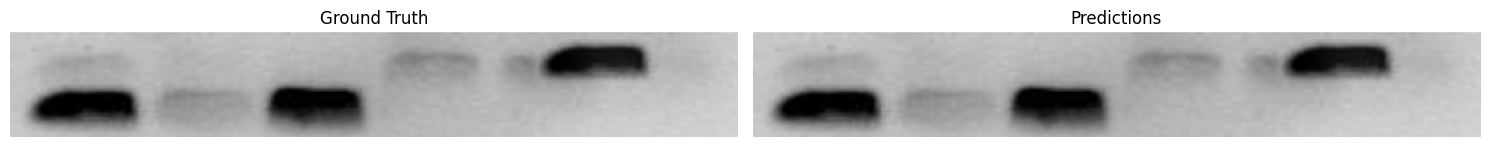

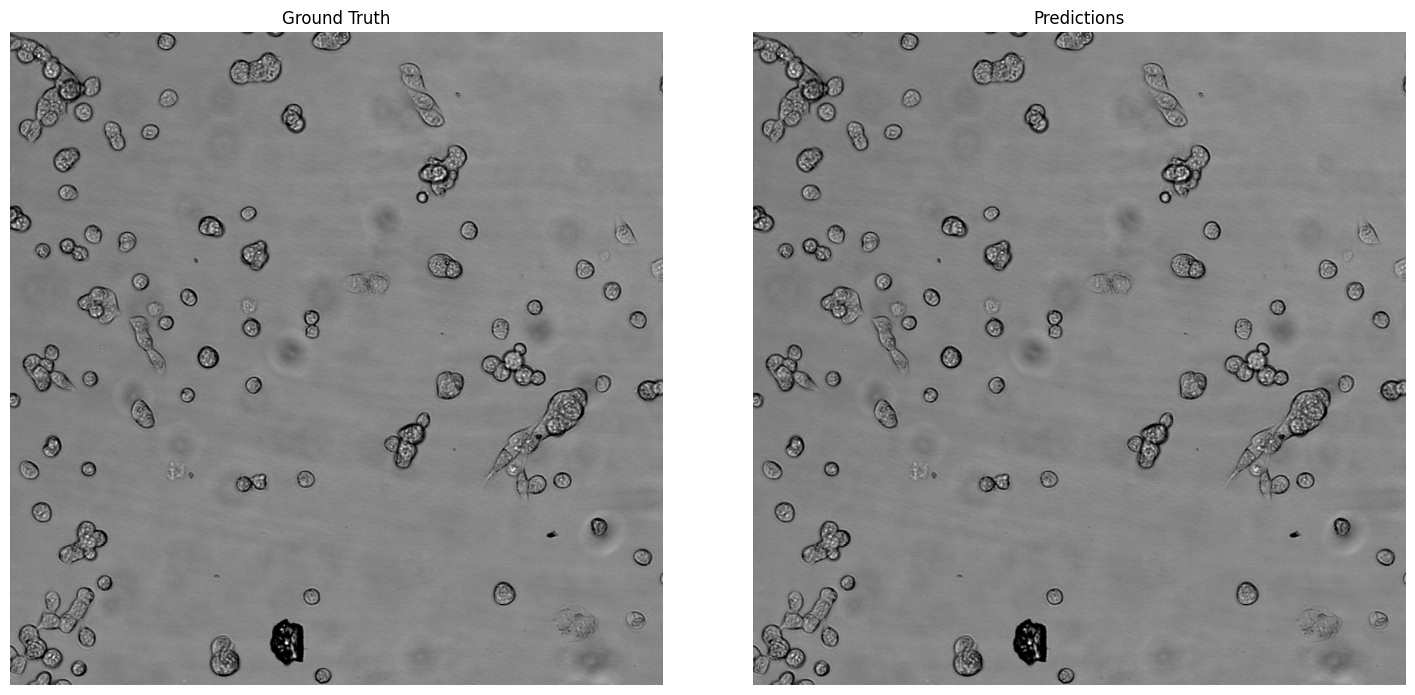

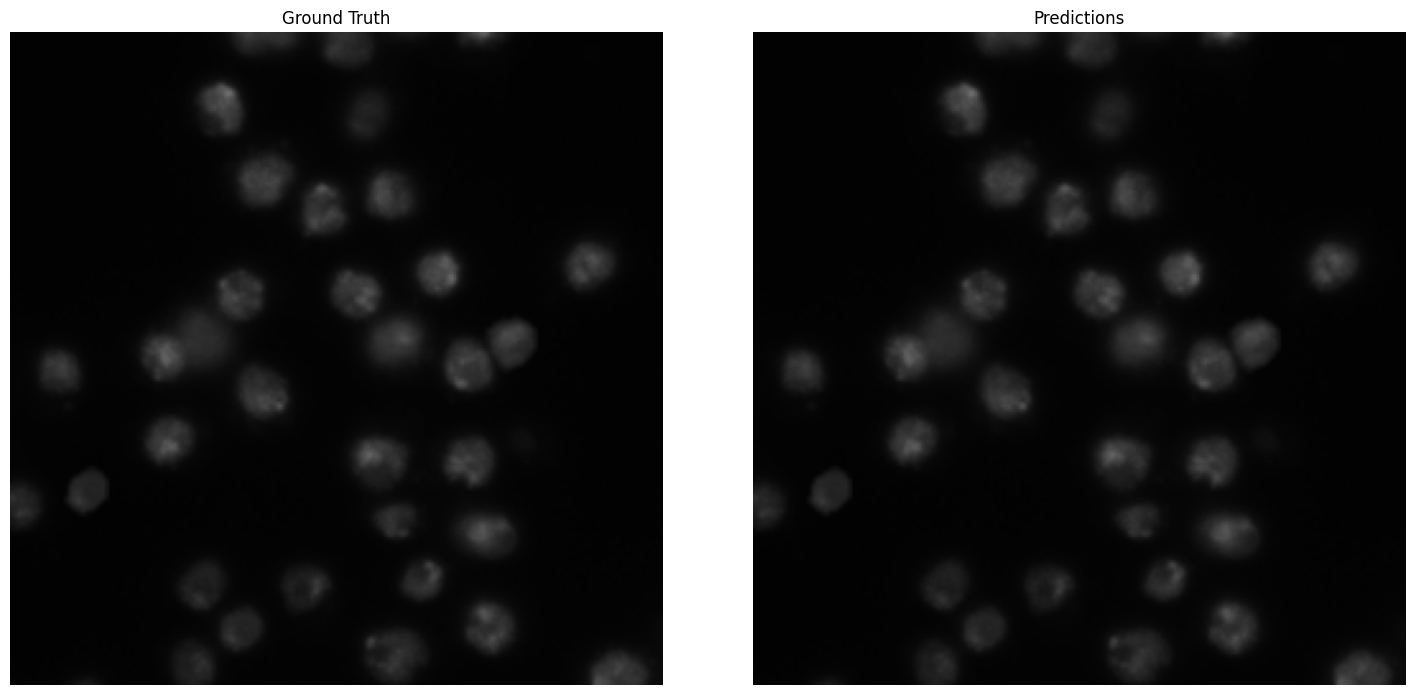

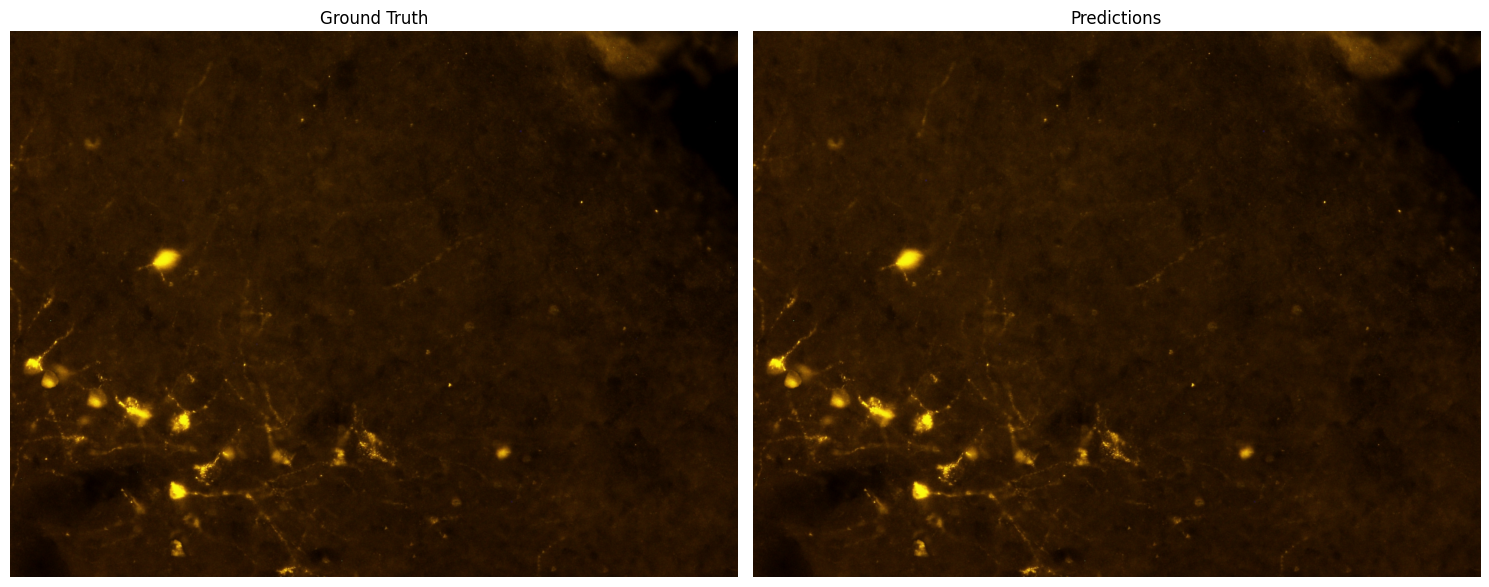

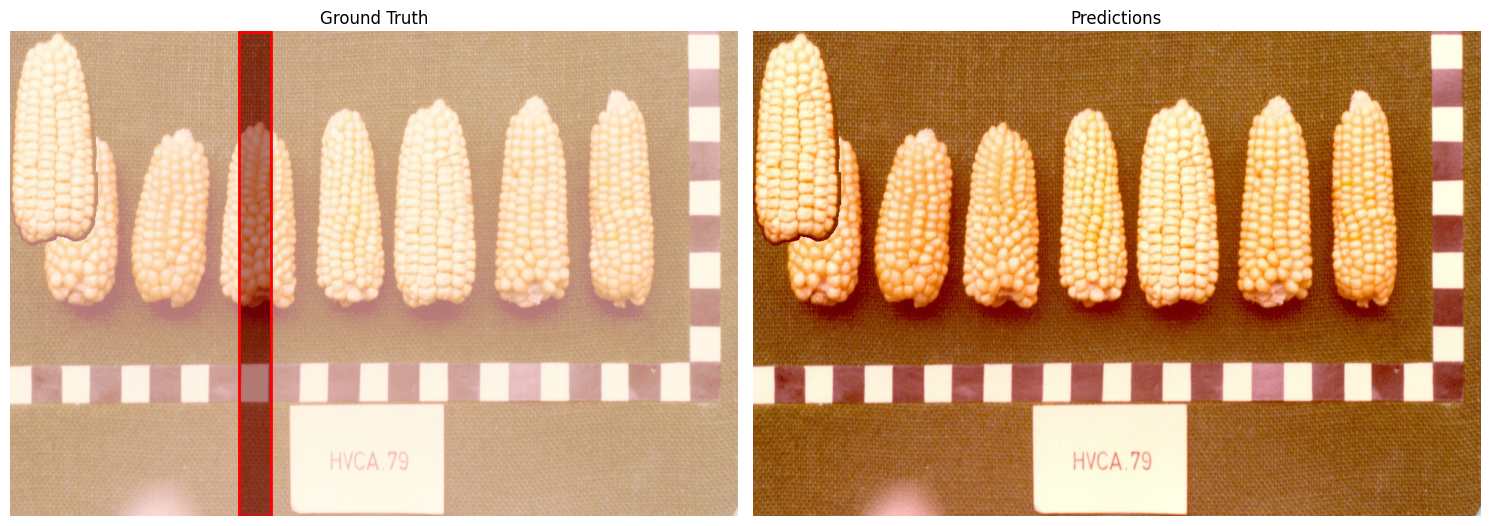

Saved 10 predictions to predictions/


In [31]:
def visualize_predictions(model, dataset, device, num_samples=5, save_dir='predictions'):
    """Visualize model predictions on validation images."""
    os.makedirs(save_dir, exist_ok=True)
    model.eval()

    # Get random samples
    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)

    for idx in indices:
        image, target = dataset[idx]

        with torch.no_grad():
            prediction = model([image.to(device)])[0]

        # Convert image back for visualization
        img_np = image.permute(1, 2, 0).cpu().numpy()
        img_np = (img_np * 255).astype(np.uint8)

        fig, axes = plt.subplots(1, 2, figsize=(15, 7))

        # Ground truth
        axes[0].imshow(img_np)
        axes[0].set_title('Ground Truth')
        axes[0].axis('off')
        if target['masks'].shape[0] > 0:
            mask_gt = target['masks'][0].numpy()
            axes[0].imshow(mask_gt, alpha=0.5, cmap='Reds')
            if target['boxes'].shape[0] > 0:
                box_gt = target['boxes'][0].numpy()
                rect = patches.Rectangle(
                    (box_gt[0], box_gt[1]), box_gt[2] - box_gt[0], box_gt[3] - box_gt[1],
                    linewidth=2, edgecolor='red', facecolor='none'
                )
                axes[0].add_patch(rect)

        # Predictions
        axes[1].imshow(img_np)
        axes[1].set_title('Predictions')
        axes[1].axis('off')

        # Draw predictions
        scores = prediction['scores'].cpu().numpy()
        masks = prediction['masks'].cpu().numpy()
        boxes = prediction['boxes'].cpu().numpy()

        for i in range(len(scores)):
            if scores[i] > 0.5:  # Confidence threshold
                mask = masks[i, 0] > 0.5
                axes[1].imshow(mask, alpha=0.5, cmap='Blues')

                # Draw bounding box
                box = boxes[i]
                rect = patches.Rectangle(
                    (box[0], box[1]), box[2] - box[0], box[3] - box[1],
                    linewidth=2, edgecolor='green', facecolor='none'
                )
                axes[1].add_patch(rect)
                axes[1].text(box[0], box[1], f'{scores[i]:.2f}',
                           bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f'prediction_{idx}.png'), dpi=150, bbox_inches='tight')
        plt.show()

    print(f"Saved {len(indices)} predictions to {save_dir}/")

# Generate predictions
print("Generating predictions on validation set...")
visualize_predictions(model, val_dataset, device, num_samples=10)


## 12. Inference on New Images

Example code for running inference on new images:


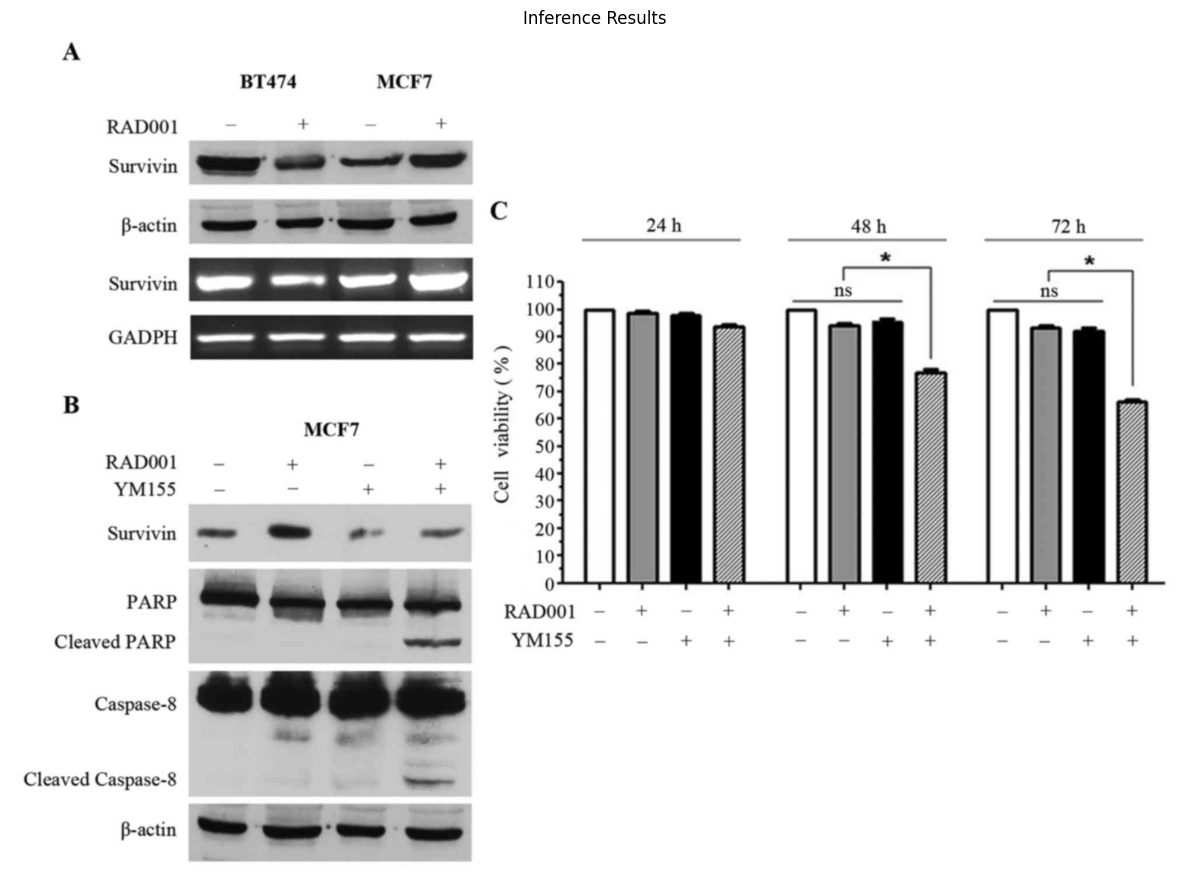

Detected 0 forged region(s) with confidence > 0.5


In [32]:
# Load the best model for inference
model.eval()

# Example: Load a test image
test_image_path = os.path.join(DATA_DIR, "test_images", "45.png")  # Update with your test image

if os.path.exists(test_image_path):
    # Load and preprocess image
    image = Image.open(test_image_path).convert('RGB')
    transform = transforms.ToTensor()
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Run inference
    with torch.no_grad():
        predictions = model(image_tensor)

    # Extract results
    pred = predictions[0]
    scores = pred['scores'].cpu().numpy()
    masks = pred['masks'].cpu().numpy()
    boxes = pred['boxes'].cpu().numpy()

    # Visualize
    fig, ax = plt.subplots(1, 1, figsize=(12, 12))
    img_np = np.array(image)
    ax.imshow(img_np)
    ax.set_title('Inference Results')
    ax.axis('off')

    # Draw predictions
    for i in range(len(scores)):
        if scores[i] > 0.5:  # Confidence threshold
            mask = masks[i, 0] > 0.5
            ax.imshow(mask, alpha=0.5, cmap='Blues')

            # Draw bounding box
            box = boxes[i]
            rect = patches.Rectangle(
                (box[0], box[1]), box[2] - box[0], box[3] - box[1],
                linewidth=2, edgecolor='green', facecolor='none'
            )
            ax.add_patch(rect)
            ax.text(box[0], box[1], f'Forged: {scores[i]:.2f}',
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    plt.tight_layout()
    plt.show()

    print(f"Detected {len(scores[scores > 0.5])} forged region(s) with confidence > 0.5")
else:
    print(f"Test image not found at: {test_image_path}")
    print("Update the path to test on your own images")
